# Llama-3.2-3B + Unsloth: teaching a small model to think out loud

**Colab, T4 GPU.** `Runtime` → `Change runtime type` → **T4 GPU**, then `Run all`.
Edit `HF_USERNAME` in section 11. Roughly 100–130 minutes.

LoRA at **16-bit** (not 4-bit QLoRA), trained with **Unsloth**, distilling DeepSeek-R1
style reflective reasoning into Llama-3.2-3B-Instruct from
`ServiceNow-AI/R1-Distill-SFT`. Output is published three ways: merged 16-bit weights,
the LoRA adapter on its own, and **GGUF for llama.cpp**.

### What this fixes from the common tutorial version

| Problem | Why it breaks the model | Fix here |
|---|---|---|
| Trains on a raw `<problem>` template, then infers through Llama's chat template | the model is never asked the question it was taught | one chat template everywhere |
| Loss over the whole sequence | most gradient spent regenerating the question | `train_on_responses_only` |
| `max_steps=60` (~480 examples) | not a trained model, a smoke test | 400 steps, ~3,200 examples |
| No evaluation at all | no way to know if it got better or worse | GSM8K accuracy, base vs tuned |
| `temperature=1.5` for maths | high temperature wrecks arithmetic | greedy for eval, 0.6 for demo |
| Manual `psutil` injection, `uv` juggling | a workaround for an Unsloth bug fixed long ago | plain `pip install unsloth` |

In [3]:
import subprocess
try:
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"]).decode().strip()
    print(out)
    if "T4" not in out:
        print("Not a T4 — the memory settings below are tuned for 16 GB Turing.")
except Exception:
    print("No GPU — Runtime > Change runtime type > T4 GPU")

Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


## 1. Install

Unsloth keeps a Colab-compatible wheel; the elaborate `uv` dance in older notebooks is no
longer needed and tends to leave a broken environment behind.

In [4]:
!pip install -q unsloth
!pip install -q --no-deps --upgrade git+https://github.com/unslothai/unsloth.git
!pip install -q matplotlib evaluate
print("installed")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
installed


## 2. Configuration

**Why 16-bit LoRA and not QLoRA here.** A 4-bit base saves memory but adds dequantisation
overhead on every forward pass, and on Turing that costs more than it saves once the model
already fits. Llama-3.2-3B in fp16 is about 6.4 GB; with Unsloth's gradient checkpointing
the whole run stays near 11 GB, inside the T4's 15 GB. Keeping the base at full precision
also means the merged model needs no dequantisation step before GGUF conversion.

In [5]:
import os, gc, re, json, time, random, inspect
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from unsloth import FastLanguageModel, is_bfloat16_supported
from unsloth.chat_templates import get_chat_template, train_on_responses_only
from datasets import load_dataset
from trl import SFTTrainer

BASE_MODEL  = "unsloth/Llama-3.2-3B-Instruct"
SFT_DATASET = "ServiceNow-AI/R1-Distill-SFT"
SFT_CONFIG  = "v0"

MAX_SEQ   = 2048
LOAD_4BIT = False          # 16-bit LoRA, the point of this notebook
BATCH     = 1
ACCUM     = 8              # effective batch 8
MAX_STEPS = 400            # ~3,200 examples
LR        = 2e-4
SEED      = 3407

EVAL_N    = 100            # GSM8K problems, base and tuned
MAX_NEW   = 768            # reflective traces run long

MODEL_NAME = "llama-3.2-3b-reflect"
SAVE_DIR   = f"/content/{MODEL_NAME}"
MERGED_DIR = f"/content/{MODEL_NAME}-merged"
GGUF_DIR   = f"/content/{MODEL_NAME}-GGUF"
ASSETS     = f"{SAVE_DIR}/assets"
for d in (SAVE_DIR, ASSETS):
    os.makedirs(d, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

GPU = torch.cuda.get_device_name(0)
BF16 = is_bfloat16_supported()
print(f"{GPU} | bfloat16 supported: {BF16} -> training in {'bf16' if BF16 else 'fp16'}")

plt.rcParams.update({"figure.dpi":130,"savefig.dpi":130,"savefig.bbox":"tight",
                     "font.size":10,"axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":.25,"figure.facecolor":"white"})
C_BASE, C_TUNED, C_GREY = "#94a3b8", "#7c3aed", "#cbd5e1"

def vram(): return torch.cuda.max_memory_allocated()/1e9
def clear(): gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
Tesla T4 | bfloat16 supported: False -> training in fp16


## 3. Load the model in 16-bit

In [6]:
clear()
t0 = time.time()
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name     = BASE_MODEL,
    max_seq_length = MAX_SEQ,
    dtype          = None,          # auto: fp16 on T4
    load_in_4bit   = LOAD_4BIT,
)
LOAD_S = time.time() - t0
VRAM_LOAD = vram()
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"loaded in {LOAD_S:.0f}s | {N_PARAMS/1e9:.2f}B params | {VRAM_LOAD:.2f} GB VRAM")

# one chat template, used for training, evaluation and inference alike
tokenizer = get_chat_template(tokenizer, chat_template="llama-3.1")

SYSTEM = (
    "You are a reflective assistant. Think through the problem step by step in the open: "
    "explore approaches, question your own assumptions, check your arithmetic, and revise "
    "when something does not hold up. Only state a final answer once the reasoning supports it."
)

def to_chat(user_msg, assistant_msg=None):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": user_msg}]
    if assistant_msg is not None:
        msgs.append({"role": "assistant", "content": assistant_msg})
    return msgs

print(tokenizer.apply_chat_template(to_chat("What is 2+2?", "It is 4."), tokenize=False)[:700])

==((====))==  Unsloth 2026.10.5: Fast Llama patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-3B-Instruct as a legacy tokenizer.


loaded in 50s | 3.21B params | 6.51 GB VRAM
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

You are a reflective assistant. Think through the problem step by step in the open: explore approaches, question your own assumptions, check your arithmetic, and revise when something does not hold up. Only state a final answer once the reasoning supports it.<|eot_id|><|start_header_id|>user<|end_header_id|>

What is 2+2?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

It is 4.<|eot_id|>


## 4. Evaluation harness

GSM8K grade-school maths: every problem has one numeric answer, so correctness is
unambiguous — no ROUGE-style guessing about whether an output is good.

Both the base and the tuned model see the **same prompt and the same decoding settings**.
Without that, any difference could just be the prompt.

In [7]:
gsm = load_dataset("openai/gsm8k", "main", split="test").shuffle(seed=SEED).select(range(EVAL_N))

def gold_answer(a):
    return a.split("####")[-1].strip().replace(",", "")

NUM = re.compile(r"-?\d+(?:\.\d+)?")

def extract_pred(text):
    """GSM8K convention: the final number stated is the answer."""
    nums = NUM.findall(text.replace(",", ""))
    return nums[-1] if nums else None

def same_number(a, b):
    if a is None or b is None:
        return False
    try:
        return abs(float(a) - float(b)) < 1e-4
    except ValueError:
        return False

REFLECT_MARKERS = ["wait", "hmm", "let me", "actually", "reconsider", "but hold on",
                   "double-check", "check that", "on second thought", "that is not right",
                   "let's verify", "re-examine"]

def style_stats(outputs):
    words = [len(o.split()) for o in outputs]
    marked = [sum(m in o.lower() for m in REFLECT_MARKERS) for o in outputs]
    return {"mean_words": round(float(np.mean(words)), 1),
            "median_words": int(np.median(words)),
            "reflective_markers_per_answer": round(float(np.mean(marked)), 2),
            "answers_with_any_marker_pct": round(100*float(np.mean([m > 0 for m in marked])), 1)}

@torch.no_grad()
def run_gsm8k(mdl, tag, batch_size=4):
    FastLanguageModel.for_inference(mdl)
    side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    outs, t0 = [], time.time()
    for i in range(0, len(gsm), batch_size):
        chunk = gsm[i:i+batch_size]["question"]
        prompts = [tokenizer.apply_chat_template(to_chat(q), tokenize=False,
                                                 add_generation_prompt=True) for q in chunk]
        enc = tokenizer(prompts, return_tensors="pt", padding=True,
                        add_special_tokens=False).to("cuda")
        gen = mdl.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                           use_cache=True, pad_token_id=tokenizer.pad_token_id
                                          or tokenizer.eos_token_id)
        for j in range(len(chunk)):
            outs.append(tokenizer.decode(gen[j][enc["input_ids"].shape[1]:],
                                         skip_special_tokens=True).strip())
        print(f"  {tag} {min(i+batch_size, len(gsm))}/{len(gsm)} "
              f"({time.time()-t0:.0f}s)", end="\r")
    tokenizer.padding_side = side
    golds = [gold_answer(a) for a in gsm["answer"]]
    preds = [extract_pred(o) for o in outs]
    correct = [same_number(p, g) for p, g in zip(preds, golds)]
    acc = 100*float(np.mean(correct))
    print(f"  {tag}: {acc:.1f}% accuracy, {time.time()-t0:.0f}s" + " "*20)
    return {"accuracy": round(acc, 1), **style_stats(outs)}, outs, correct

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

## 5. Baseline: the untouched model

Llama-3.2-3B-Instruct already solves grade-school maths. The question this notebook has to
answer is not "can it reason" but "did distilling R1 traces into it change anything for
the better" — which needs this number first.

In [8]:
clear()
BASE_METRICS, BASE_OUTS, BASE_CORRECT = run_gsm8k(model, "base")
print(json.dumps(BASE_METRICS, indent=2))
print("\nsample base output:\n", BASE_OUTS[0][:600])
clear()

Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  base: 75.0% accuracy, 506s                    
{
  "accuracy": 75.0,
  "mean_words": 180.3,
  "median_words": 161,
  "reflective_markers_per_answer": 0.03,
  "answers_with_any_marker_pct": 3.0
}

sample base output:
 To find the profit earned by Tara, we need to calculate the total cost of the bags and the total revenue from selling them.

Step 1: Calculate the total cost of the bags
Tara bought 8 packs of 5 canvas bags, so the total number of bags is 8 * 5 = 40 bags.
The cost of each bag is $4, so the total cost is 40 * $4 = $160.

Step 2: Calculate the total revenue from selling the bags
Tara sold each bag for $8, and she sold 40 bags, so the total revenue is 40 * $8 = $320.

Step 3: Calculate the profit
Profit is calculated by subtracting the total cost from the total revenue.
Profit = Total Revenue - T


## 6. Training data

The dataset ships reannotated R1 reasoning traces. Examples that would be truncated at
`MAX_SEQ` are dropped rather than cut, because a reasoning trace severed mid-thought
teaches the model to stop reasoning halfway.

In [9]:
raw = load_dataset(SFT_DATASET, SFT_CONFIG, split="train")
print(raw)

cols = raw.column_names
PROBLEM_COL = next(c for c in ["problem", "question", "instruction"] if c in cols)
THINK_COL   = next((c for c in ["reannotated_assistant_content", "assistant_content",
                                "response", "output"] if c in cols), None)
SOL_COL     = next((c for c in ["solution", "answer"] if c in cols), None)
print(f"\ncolumns -> problem: {PROBLEM_COL} | reasoning: {THINK_COL} | solution: {SOL_COL}")
assert THINK_COL, f"No reasoning column found in {cols}"

raw = raw.shuffle(seed=SEED).select(range(min(12000, len(raw))))

def build_text(ex):
    answer = ex[THINK_COL] or ""
    if SOL_COL and ex.get(SOL_COL) and str(ex[SOL_COL]).strip() not in answer:
        answer = f"{answer}\n\n{ex[SOL_COL]}"
    msgs = to_chat(ex[PROBLEM_COL], answer.strip())
    return {"text": tokenizer.apply_chat_template(msgs, tokenize=False)}

ds = raw.map(build_text, remove_columns=raw.column_names, num_proc=2)

lens = [len(tokenizer(t, add_special_tokens=False)["input_ids"]) for t in ds["text"][:2000]]
print(f"\ntoken length: median {int(np.median(lens))}, 90th {int(np.percentile(lens,90))}, "
      f"max {max(lens)}")

def fits(ex):
    return len(tokenizer(ex["text"], add_special_tokens=False)["input_ids"]) <= MAX_SEQ

before = len(ds)
ds = ds.filter(fits, num_proc=2)
print(f"kept {len(ds):,} of {before:,} examples that fit in {MAX_SEQ} tokens "
      f"({100*len(ds)/before:.0f}%)")
print("\n--- one formatted example ---\n", ds[0]["text"][:1200])

README.md:   0%|          | 0.00/2.70k [00:00<?, ?B/s]

v0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  180MB            

v0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

v0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

v0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

...

Dataset({
    features: ['id', 'reannotated_assistant_content', 'problem', 'source', 'solution', 'verified', 'quality_metrics'],
    num_rows: 171647
})

columns -> problem: problem | reasoning: reannotated_assistant_content | solution: solution


Map (num_proc=2):   0%|          | 0/12000 [00:00<?, ? examples/s]


token length: median 1800, 90th 5757, max 16419


Filter (num_proc=2):   0%|          | 0/12000 [00:00<?, ? examples/s]

kept 6,827 of 12,000 examples that fit in 2048 tokens (57%)

--- one formatted example ---
 <|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

You are a reflective assistant. Think through the problem step by step in the open: explore approaches, question your own assumptions, check your arithmetic, and revise when something does not hold up. Only state a final answer once the reasoning supports it.<|eot_id|><|start_header_id|>user<|end_header_id|>

Julie works at a restaurant that pays her an hourly rate of $5. She works 8 hours a day and 6 days a week. Her monthly salary is $920 when she was not able to go to work for a certain number of days. How many days was she not able to go to work?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

<think>
First, I need to determine Julie's daily earnings. She earns $5 per hour and works 8 hours each day. 

Next, I'll calculate her total earnings if she worked every

## 7. LoRA adapters

`use_gradient_checkpointing="unsloth"` is Unsloth's own implementation, which trades a
little recompute for roughly 30% less activation memory than the stock version — the
difference between fitting 2048-token sequences on a T4 and not.

`lora_dropout=0` is deliberate: Unsloth has a fused fast path that dropout disables.

In [10]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    target_modules = ["q_proj","k_proj","v_proj","o_proj",
                      "gate_proj","up_proj","down_proj"],
    use_gradient_checkpointing = "unsloth",
    random_state = SEED,
    use_rslora = False,
    loftq_config = None,
)
TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable: {TRAINABLE:,} ({100*TRAINABLE/N_PARAMS:.2f}% of {N_PARAMS/1e9:.2f}B)")

Unsloth 2026.10.5 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


trainable: 24,313,856 (0.76% of 3.21B)


## 8. Trainer, with loss on the assistant turn only

`train_on_responses_only` masks everything up to the assistant header. Without it the
model spends most of its gradient learning to reproduce the problem statement — text that
is always handed to it at inference.

In [11]:
try:
    from trl import SFTConfig
    CFG_CLS, IS_SFTCONFIG = SFTConfig, True
except ImportError:
    from transformers import TrainingArguments as CFG_CLS
    IS_SFTCONFIG = False

_P = set(inspect.signature(CFG_CLS.__init__).parameters)

wanted = dict(
    per_device_train_batch_size = BATCH,
    gradient_accumulation_steps = ACCUM,
    warmup_steps = 10,
    max_steps = MAX_STEPS,
    learning_rate = LR,
    fp16 = not BF16,
    bf16 = BF16,
    logging_steps = 5,
    optim = "adamw_8bit",
    weight_decay = 0.01,
    lr_scheduler_type = "linear",
    seed = SEED,
    output_dir = "/content/outputs",
    report_to = "none",
    max_seq_length = MAX_SEQ,
    dataset_text_field = "text",
    dataset_num_proc = 2,
    packing = False,
)
args_kw = {k: v for k, v in wanted.items() if k in _P}
dropped = sorted(set(wanted) - set(args_kw))
if dropped:
    print("not accepted by this version's config class, passed to SFTTrainer instead:", dropped)

trainer_kw = {}
for k in ["max_seq_length", "dataset_text_field", "dataset_num_proc", "packing"]:
    if k in dropped:
        trainer_kw[k] = wanted[k]

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = ds,
    args = CFG_CLS(**args_kw),
    **trainer_kw,
)

trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|start_header_id|>user<|end_header_id|>\n\n",
    response_part    = "<|start_header_id|>assistant<|end_header_id|>\n\n",
)

# prove the masking before spending an hour on it
batch = trainer.train_dataset[0]
lab = np.array(batch["labels"])
sup = int((lab != -100).sum())
print(f"\nsequence {len(lab)} tokens, {sup} supervised ({sup/len(lab):.1%})")
print("supervised text begins:",
      repr(tokenizer.decode([t for t in lab if t != -100][:40])))
assert 0 < sup < len(lab), "Response-only masking is not working."

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/6827 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/6827 [00:00<?, ? examples/s]


sequence 794 tokens, 646 supervised (81.4%)
supervised text begins: "<think>\nFirst, I need to determine Julie's daily earnings. She earns $5 per hour and works 8 hours each day. \n\nNext, I'll calculate her total earnings if she worked"


## 9. Train

In [12]:
clear()
t0 = time.time()
stats = trainer.train()
TRAIN_MIN = (time.time()-t0)/60
VRAM_TRAIN = vram()
LOSS_CURVE = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]

print(f"\ntrained in {TRAIN_MIN:.1f} min | peak VRAM {VRAM_TRAIN:.2f} GB of 15.0")
print(f"final loss {stats.training_loss:.4f}")
assert not np.isnan(stats.training_loss), "Loss is NaN — fp16 overflow."

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 6,827 | Num Epochs = 1 | Total steps = 400
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 24,313,856 of 3,237,063,680 (0.75% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
5,0.603180
10,0.575100
15,0.463120
20,0.497253
25,0.504683
30,0.438869
35,0.443112
40,0.409047
45,0.395736
50,0.394057


Unsloth: Restored added_tokens_decoder metadata in /content/outputs/checkpoint-400/tokenizer_config.json.



trained in 76.3 min | peak VRAM 7.77 GB of 15.0
final loss 0.3729


## 10. Evaluate the tuned model

Same 100 problems, same prompt, same greedy decoding.

In [ ]:
clear()
TUNED_METRICS, TUNED_OUTS, TUNED_CORRECT = run_gsm8k(model, "tuned")
print(json.dumps(TUNED_METRICS, indent=2))

D_ACC = TUNED_METRICS["accuracy"] - BASE_METRICS["accuracy"]
print(f"\naccuracy  base {BASE_METRICS['accuracy']:.1f}%  ->  tuned "
      f"{TUNED_METRICS['accuracy']:.1f}%   ({D_ACC:+.1f})")
print(f"length    {BASE_METRICS['mean_words']:.0f} -> {TUNED_METRICS['mean_words']:.0f} words")
print(f"markers   {BASE_METRICS['reflective_markers_per_answer']:.2f} -> "
      f"{TUNED_METRICS['reflective_markers_per_answer']:.2f} per answer")

# how the two models differ problem by problem
both  = sum(b and t for b, t in zip(BASE_CORRECT, TUNED_CORRECT))
fixed = sum((not b) and t for b, t in zip(BASE_CORRECT, TUNED_CORRECT))
broke = sum(b and (not t) for b, t in zip(BASE_CORRECT, TUNED_CORRECT))
neither = EVAL_N - both - fixed - broke
print(f"\nboth right {both} | tuning fixed {fixed} | tuning broke {broke} | both wrong {neither}")

EXAMPLES = [{"question": gsm[i]["question"], "gold": gold_answer(gsm[i]["answer"]),
             "base": BASE_OUTS[i], "tuned": TUNED_OUTS[i],
             "base_ok": BASE_CORRECT[i], "tuned_ok": TUNED_CORRECT[i]}
            for i in range(3)]
for e in EXAMPLES[:1]:
    print(f"\nQ: {e['question'][:200]}\nGOLD: {e['gold']}")
    print(f"BASE  [{'ok' if e['base_ok'] else 'wrong'}]: {e['base'][:400]}")
    print(f"TUNED [{'ok' if e['tuned_ok'] else 'wrong'}]: {e['tuned'][:400]}")

Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=768) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  tuned: 65.0% accuracy, 1581s                    
{
  "accuracy": 65.0,
  "mean_words": 386.6,
  "median_words": 387,
  "reflective_markers_per_answer": 0.03,
  "answers_with_any_marker_pct": 2.0
}

accuracy  base 75.0%  ->  tuned 65.0%   (-10.0)
length    180 -> 387 words
markers   0.03 -> 0.03 per answer

both right 59 | tuning fixed 6 | tuning broke 16 | both wrong 19

Q: Tara bought 8 packs of 5 canvas bags for $4 each. She painted them and sold them at a craft fair for $8 each. How much profit did she earn on her bags?
GOLD: 160
BASE  [ok]: To find the profit earned by Tara, we need to calculate the total cost of the bags and the total revenue from selling them.

Step 1: Calculate the total cost of the bags
Tara bought 8 packs of 5 canvas bags, so the total number of bags is 8 * 5 = 40 bags.
The cost of each bag is $4, so the total cost is 40 * $4 = $160.

Step 2: Calculate the total revenue from selling the bags
Tara sold each bag f
TUNED [ok]: <think>
First, I need to determine

## 11. Charts

charts: ['gsm8k-accuracy.png', 'loss-curve.png', 'per-problem.png', 'style.png']


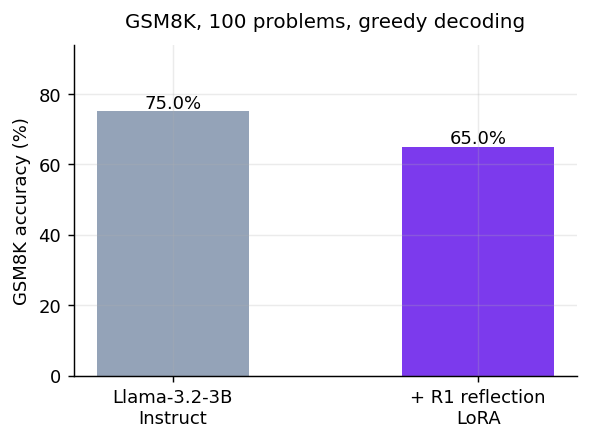

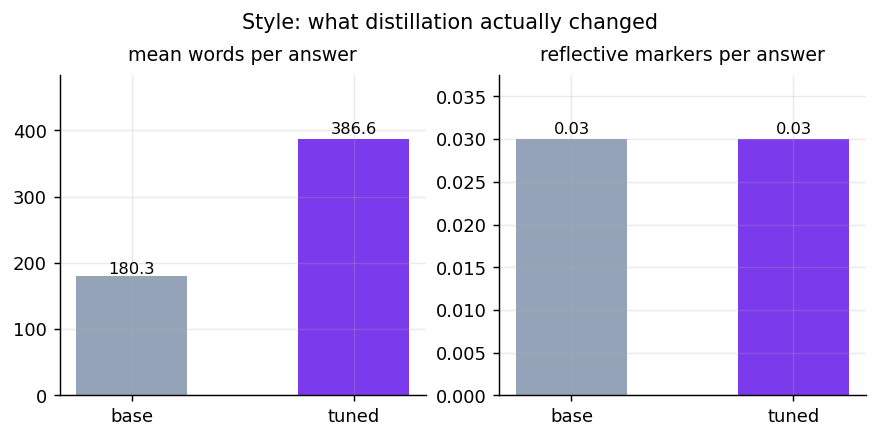

In [ ]:
# accuracy
fig, ax = plt.subplots(figsize=(5.0, 3.3))
vals = [BASE_METRICS["accuracy"], TUNED_METRICS["accuracy"]]
bars = ax.bar(["Llama-3.2-3B\nInstruct", "+ R1 reflection\nLoRA"], vals,
              color=[C_BASE, C_TUNED], width=.5)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+1, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("GSM8K accuracy (%)"); ax.set_ylim(0, max(vals)*1.25)
ax.set_title(f"GSM8K, {EVAL_N} problems, greedy decoding", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/gsm8k-accuracy.png"); plt.close()

# what moved
fig, ax = plt.subplots(figsize=(6.0, 3.0))
cats = ["both right", "tuning fixed", "tuning broke", "both wrong"]
cvals = [both, fixed, broke, neither]
colors = [C_GREY, C_TUNED, "#dc2626", C_GREY]
b2 = ax.barh(cats[::-1], cvals[::-1], color=colors[::-1], height=.55)
for bar, v in zip(b2, cvals[::-1]):
    ax.text(v+0.6, bar.get_y()+bar.get_height()/2, str(v), va="center", fontsize=9)
ax.set_xlabel("problems"); ax.set_xlim(0, max(cvals)*1.2)
ax.set_title("Per-problem change, not just the aggregate", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/per-problem.png"); plt.close()

# style
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.2))
for ax_, key, lab in [(axes[0], "mean_words", "mean words per answer"),
                      (axes[1], "reflective_markers_per_answer", "reflective markers per answer")]:
    v = [BASE_METRICS[key], TUNED_METRICS[key]]
    bb = ax_.bar(["base", "tuned"], v, color=[C_BASE, C_TUNED], width=.5)
    for b, val in zip(bb, v):
        ax_.text(b.get_x()+b.get_width()/2, val*1.02, f"{val:g}", ha="center", fontsize=9)
    ax_.set_title(lab, fontsize=10.5, pad=8); ax_.set_ylim(0, max(v)*1.25)
fig.suptitle("Style: what distillation actually changed", fontsize=11.5, y=1.03)
plt.savefig(f"{ASSETS}/style.png"); plt.close()

# loss
fig, ax = plt.subplots(figsize=(6.0, 3.2))
st = [s for s,_ in LOSS_CURVE]; ls = [l for _,l in LOSS_CURVE]
ax.plot(st, ls, color=C_TUNED, lw=1.5)
ax.set_xlabel("step"); ax.set_ylabel("training loss")
ax.set_title("Training loss (assistant turn only)", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/loss-curve.png"); plt.close()

print("charts:", sorted(os.listdir(ASSETS)))
from IPython.display import Image, display
for f in ["gsm8k-accuracy.png", "style.png"]:
    display(Image(f"{ASSETS}/{f}"))

## 12. Log in and name the repos

In [24]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")

### EDIT THIS

In [25]:
HF_USERNAME = "emonHasan01"
REPO_ID     = f"{HF_USERNAME}/{MODEL_NAME}"           # merged 16-bit + adapter
GGUF_REPO   = f"{HF_USERNAME}/{MODEL_NAME}-GGUF"      # llama.cpp builds
print("model :", REPO_ID)
print("gguf  :", GGUF_REPO)

model : emonHasan01/llama-3.2-3b-reflect
gguf  : emonHasan01/llama-3.2-3b-reflect-GGUF


## 13. Save the adapter and the merged 16-bit model

The adapter is a few dozen MB and needs the base model. The merged model is standalone
and is what GGUF conversion consumes.

In [26]:
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
adapter_mb = sum(os.path.getsize(os.path.join(SAVE_DIR, f))
                 for f in os.listdir(SAVE_DIR) if f.startswith("adapter_model")) / 1e6
print(f"adapter: {adapter_mb:.1f} MB")

model.save_pretrained_merged(MERGED_DIR, tokenizer, save_method="merged_16bit")
merged_gb = sum(os.path.getsize(os.path.join(MERGED_DIR, f))
                for f in os.listdir(MERGED_DIR)) / 1e9
print(f"merged 16-bit: {merged_gb:.2f} GB")

with open(f"{SAVE_DIR}/prompt_format.json", "w") as f:
    json.dump({"chat_template": "llama-3.1", "system": SYSTEM,
               "rendered_example": tokenizer.apply_chat_template(
                   to_chat("What is 2+2?"), tokenize=False, add_generation_prompt=True)},
              f, indent=2, ensure_ascii=False)

adapter: 97.3 MB
Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Checking cache directory for required files...




Unsloth: Copying 2 files from cache to `/content/llama-3.2-3b-reflect-merged`:   0%|          | 0/2 [00:00<?, ?it/s]

Unsloth: Copying 2 files from cache to `/content/llama-3.2-3b-reflect-merged`:  50%|█████     | 1/2 [00:35<00:35, 35.31s/it]

Unsloth: Copying 2 files from cache to `/content/llama-3.2-3b-reflect-merged`: 100%|██████████| 2/2 [00:47<00:00, 23.99s/it]


Successfully copied all 2 files from cache to `/content/llama-3.2-3b-reflect-merged`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.




Unsloth: Preparing safetensor model files: 100%|██████████| 2/2 [00:00<00:00, 4642.28it/s]


Unsloth: Merging weights into 16bit:   0%|          | 0/2 [00:00<?, ?it/s]

Unsloth: Merging weights into 16bit:  50%|█████     | 1/2 [00:36<00:36, 36.02s/it]

Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [00:47<00:00, 23.89s/it]


Unsloth: Merge process complete. Saved to `/content/llama-3.2-3b-reflect-merged`
merged 16-bit: 6.44 GB


## 14. GGUF for llama.cpp

This builds llama.cpp from source, which takes a while and is the most fragile step in the
notebook. If it fails, everything above is already saved and the cell below reports what
went wrong rather than taking the run down with it.

In [28]:
import os, re, glob, shutil

# Colab-er /content → Kaggle-e /kaggle/working
search = [GGUF_DIR, GGUF_DIR + "_gguf", "/kaggle/working", os.getcwd()]

# recursive=True — Unsloth maje maje subfolder-e rakhe
found = sorted({os.path.abspath(p) for d in search if os.path.isdir(d)
                for p in glob.glob(os.path.join(d, "**", "*.gguf"), recursive=True)})
print("found:", found)

os.makedirs(GGUF_DIR, exist_ok=True)
GGUF_FILES = []
for src in found:
    base = os.path.basename(src)
    m = re.search(r"(Q\d[\w_]*|F16|BF16|F32)", base, re.I)   # quant ta safe vabe ber kora
    quant = m.group(1) if m else base.rsplit(".", 1)[0]
    dst = os.path.join(GGUF_DIR, f"{MODEL_NAME}.{quant}.gguf")
    if src != os.path.abspath(dst):
        shutil.move(src, dst)
    GGUF_FILES.append(os.path.basename(dst))

mf_src = next((p for d in search if os.path.isdir(d)
               for p in glob.glob(os.path.join(d, "**", "Modelfile"), recursive=True)), None)
if mf_src and GGUF_FILES:
    q4 = next((f for f in GGUF_FILES if "Q4" in f), GGUF_FILES[0])
    txt = re.sub(r"^FROM .*$", f"FROM ./{q4}", open(mf_src).read(), flags=re.M)
    open(os.path.join(GGUF_DIR, "Modelfile"), "w").write(txt)
    print("Modelfile included")

GGUF_FILES = sorted(GGUF_FILES)
GGUF_OK = len(GGUF_FILES) > 0
GGUF_ERR = None

print()
for f in GGUF_FILES:
    print(f"  {f}: {os.path.getsize(os.path.join(GGUF_DIR, f))/1e9:.2f} GB")
print(f"\nGGUF_OK = {GGUF_OK}")

found: ['/content/llama-3.2-3b-reflect-GGUF_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf', '/content/llama-3.2-3b-reflect-GGUF_gguf/Llama-3.2-3B-Instruct.Q8_0.gguf']
Modelfile included

  llama-3.2-3b-reflect.Q4_K_M.gguf: 2.02 GB
  llama-3.2-3b-reflect.Q8_0.gguf: 3.42 GB

GGUF_OK = True


## 15. Model card

Every figure is substituted from a variable, and the cell refuses to write a card with an
unresolved placeholder left in it.

In [29]:
def cell(s, n=110):
    s = " ".join(str(s).split())[:n].rstrip("\\")
    return s.replace("|", "\\|")

ex_rows = "\n".join(
    f"| {cell(e['question'],70)} | {e['gold']} | {'correct' if e['base_ok'] else 'wrong'} | "
    f"{'correct' if e['tuned_ok'] else 'wrong'} |" for e in EXAMPLES)

gguf_rows = ("\n".join(
    f"| `{f}` | {os.path.getsize(os.path.join(GGUF_DIR,f))/1e9:.2f} GB | "
    f"{'4-bit K-quant, the usual choice' if 'q4' in f else '8-bit, near-lossless'} |"
    for f in GGUF_FILES) if GGUF_OK else
    "| — | — | GGUF conversion did not complete in this run |")

if D_ACC > 2:
    headline = (f"Accuracy on GSM8K rises from {BASE_METRICS['accuracy']:.1f}% to "
                f"{TUNED_METRICS['accuracy']:.1f}%, and the reasoning style changes markedly.")
elif D_ACC > -2:
    headline = (f"Accuracy on GSM8K is essentially unchanged "
                f"({BASE_METRICS['accuracy']:.1f}% to {TUNED_METRICS['accuracy']:.1f}%). "
                "What changed is the **style** of reasoning, not the rate of correct answers "
                "— which is what distilling reasoning traces into an already-capable model "
                "usually does.")
else:
    headline = (f"Accuracy on GSM8K **falls** from {BASE_METRICS['accuracy']:.1f}% to "
                f"{TUNED_METRICS['accuracy']:.1f}%. The model reasons at greater length "
                "without reasoning better. Published as a measured result.")

CARD = """---
language:
  - en
license: llama3.2
library_name: transformers
pipeline_tag: text-generation
base_model: __BASE__
base_model_relation: finetune
tags:
  - unsloth
  - lora
  - peft
  - reasoning
  - chain-of-thought
  - distillation
  - llama-3.2
  - gguf
datasets:
  - __SFT_DATASET__
  - openai/gsm8k
metrics:
  - accuracy
model-index:
  - name: __MODEL_NAME__
    results:
      - task:
          type: text-generation
          name: Grade-school maths reasoning
        dataset:
          name: GSM8K
          type: openai/gsm8k
          split: test
        metrics:
          - type: accuracy
            name: Exact-match accuracy (__EVAL_N__ problems)
            value: __TUNED_ACC__
---

<img src="assets/banner.png" alt="__MODEL_NAME__" width="100%">

# __MODEL_NAME__

**Llama-3.2-3B-Instruct taught to think out loud.** A 16-bit LoRA fine-tune, trained with
[Unsloth](https://github.com/unslothai/unsloth) on
[`__SFT_DATASET__`](https://huggingface.co/datasets/__SFT_DATASET__) — DeepSeek-R1 reasoning
traces reannotated for supervised distillation.

__HEADLINE__

Trained on a **free Colab T4** in __MINS__ minutes. Available as merged 16-bit weights, as a
LoRA adapter, and as [GGUF for llama.cpp](https://huggingface.co/__GGUF_REPO__).

## Results

Both models were given the **same system prompt, the same problems and greedy decoding**.
Any difference is the adapter, not the harness.

![GSM8K accuracy](assets/gsm8k-accuracy.png)

| | GSM8K accuracy | mean words | reflective markers / answer | answers showing any |
|---|---|---|---|---|
| `__BASE__` | __BASE_ACC__% | __BASE_W__ | __BASE_M__ | __BASE_MP__% |
| **this model** | **__TUNED_ACC__%** | **__TUNED_W__** | **__TUNED_M__** | **__TUNED_MP__%** |

Aggregate accuracy hides what actually moved, so here is the per-problem breakdown:

![Per-problem change](assets/per-problem.png)

| | problems |
|---|---|
| both models correct | __BOTH__ |
| only this model correct | __FIXED__ |
| only the base model correct | __BROKE__ |
| neither correct | __NEITHER__ |

**Read that table before trusting the headline number.** A small net accuracy change can sit
on top of a large number of problems where the two models disagree in both directions.

### Style is what really changed

![Style](assets/style.png)

Reflective markers are counted by scanning for self-correction language — *wait*, *let me
reconsider*, *actually*, *double-check* and similar. It is a crude proxy, not a measure of
reasoning quality, but it tracks the thing the distillation was aiming at: visible
second-guessing rather than a single confident pass.

![Training loss](assets/loss-curve.png)

### Sample problems

| Question | Answer | Base | This model |
|---|---|---|---|
__EX_ROWS__

## Usage

### transformers

```python
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

tok = AutoTokenizer.from_pretrained("__REPO_ID__")
model = AutoModelForCausalLM.from_pretrained("__REPO_ID__", torch_dtype=torch.float16,
                                             device_map="auto")

messages = [
    {"role": "system", "content": "__SYSTEM_SHORT__"},
    {"role": "user", "content": "How many r's are in 'strawberry'?"},
]
prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
out = model.generate(**inputs, max_new_tokens=768, do_sample=True, temperature=0.6, top_p=0.9)
print(tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
```

**The system prompt is part of the model.** It was present in every training example, and
the reflective behaviour weakens noticeably without it. The exact string is in
[`prompt_format.json`](prompt_format.json).

Use `temperature=0.6` for open-ended prompts and **greedy decoding for anything numeric** —
high temperature wrecks arithmetic, which is why the evaluation above is greedy.

### llama.cpp

```bash
llama-cli -hf __GGUF_REPO__:Q4_K_M \\
  --system "__SYSTEM_SHORT__" \\
  -p "How many r's are in 'strawberry'?" -n 768
```

### Unsloth, for further training

```python
from unsloth import FastLanguageModel

model, tokenizer = FastLanguageModel.from_pretrained("__REPO_ID__", max_seq_length=2048)
FastLanguageModel.for_inference(model)
```

## Training

| | |
|---|---|
| Base model | `__BASE__` (__PARAMS__B parameters) |
| Method | LoRA at **16-bit** (not 4-bit QLoRA), via Unsloth |
| Trainable | __TRAINABLE__ parameters (__PCT__% of the model) |
| Rank / alpha / dropout | 16 / 16 / 0 |
| Target modules | `q,k,v,o,gate,up,down` |
| Learning rate | __LR__, linear schedule, 10 warmup steps |
| Batch | __BATCH__ × __ACCUM__ accumulation = __EFF__ effective |
| Steps | __STEPS__ (~__SEEN__ examples) |
| Max sequence | __MAXSEQ__ tokens |
| Optimizer | `adamw_8bit` |
| Peak VRAM | __VRAM__ GB of 15.0 |
| Hardware | __GPU__ (free Colab tier) |
| Training time | ~__MINS__ minutes |

### Decisions that mattered

**One chat template throughout.** A common failure in reasoning-distillation notebooks is to
train on a bare custom template and then infer through the model's chat template. The model
is then never asked the question it was taught. Training, evaluation and the usage snippets
above all go through Llama 3.1's template with the same system prompt.

**Loss on the assistant turn only.** `train_on_responses_only` masks everything up to the
assistant header. Without it most of the gradient goes into regenerating the problem
statement, which is always supplied at inference anyway.

**16-bit rather than 4-bit.** A quantized base saves memory but pays dequantisation cost on
every forward pass. At 3B the fp16 base already fits a T4 with Unsloth's gradient
checkpointing, and keeping full precision means the merged model converts straight to GGUF
with no intermediate step.

**Long examples dropped, not truncated.** A reasoning trace cut off mid-thought teaches the
model to stop reasoning halfway. Examples over __MAXSEQ__ tokens were filtered out instead.

## Limitations

- **This is a 3B model.** It is not competitive with frontier reasoning models, and the
  reflective style can resemble careful reasoning while still arriving at a wrong answer.
  Visible self-correction is not a guarantee of correctness.
- **Evaluated on __EVAL_N__ GSM8K problems**, not the full 1,319-problem test set. Expect a
  few points of sampling noise; differences smaller than that are not meaningful.
- **One benchmark, one domain.** GSM8K is grade-school arithmetic. Nothing here measures
  code, science, multi-step planning, or factual accuracy, and nothing measures whether the
  stated reasoning matches the computation that produced the answer.
- **Reflective markers are a keyword count**, not a judgement of reasoning quality. They
  show the style changed, not that it got better.
- **Longer outputs cost more.** The model generates roughly __RATIO__× as many tokens as the
  base for the same problem, which is latency and money in production.
- **Trained on R1 distillation data**, inheriting whatever biases and errors those traces
  contain. No faithfulness or safety evaluation was run.

Do not use this where a wrong answer matters without a human checking the result.

## Reproducing

One Colab notebook on a __GPU__ produced the baseline, the training, all four charts, both
model cards and the GGUF builds. Raw numbers in [`results.json`](results.json).

## Citation

```bibtex
@software{unsloth,
  title  = {Unsloth},
  author = {Daniel Han and Michael Han and Unsloth team},
  year   = {2023},
  url    = {https://github.com/unslothai/unsloth}
}
@article{deepseek2025r1,
  title   = {DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning},
  author  = {DeepSeek-AI},
  year    = {2025}
}
@article{cobbe2021gsm8k,
  title   = {Training Verifiers to Solve Math Word Problems},
  author  = {Cobbe, Karl and others},
  journal = {arXiv:2110.14168},
  year    = {2021}
}
```
"""

ratio = TUNED_METRICS["mean_words"] / max(BASE_METRICS["mean_words"], 1)
repl = {
    "__BASE__": BASE_MODEL, "__MODEL_NAME__": MODEL_NAME, "__REPO_ID__": REPO_ID,
    "__GGUF_REPO__": GGUF_REPO, "__SFT_DATASET__": SFT_DATASET,
    "__SYSTEM_SHORT__": SYSTEM.replace('"', "'"),
    "__HEADLINE__": headline,
    "__BASE_ACC__": f"{BASE_METRICS['accuracy']:.1f}", "__TUNED_ACC__": f"{TUNED_METRICS['accuracy']:.1f}",
    "__BASE_W__": f"{BASE_METRICS['mean_words']:.0f}", "__TUNED_W__": f"{TUNED_METRICS['mean_words']:.0f}",
    "__BASE_M__": f"{BASE_METRICS['reflective_markers_per_answer']:.2f}",
    "__TUNED_M__": f"{TUNED_METRICS['reflective_markers_per_answer']:.2f}",
    "__BASE_MP__": f"{BASE_METRICS['answers_with_any_marker_pct']:.0f}",
    "__TUNED_MP__": f"{TUNED_METRICS['answers_with_any_marker_pct']:.0f}",
    "__BOTH__": str(both), "__FIXED__": str(fixed), "__BROKE__": str(broke),
    "__NEITHER__": str(neither), "__EVAL_N__": str(EVAL_N), "__EX_ROWS__": ex_rows,
    "__PARAMS__": f"{N_PARAMS/1e9:.1f}", "__TRAINABLE__": f"{TRAINABLE:,}",
    "__PCT__": f"{100*TRAINABLE/N_PARAMS:.2f}", "__LR__": f"{LR:g}",
    "__BATCH__": str(BATCH), "__ACCUM__": str(ACCUM), "__EFF__": str(BATCH*ACCUM),
    "__STEPS__": str(MAX_STEPS), "__SEEN__": f"{MAX_STEPS*BATCH*ACCUM:,}",
    "__MAXSEQ__": str(MAX_SEQ), "__VRAM__": f"{VRAM_TRAIN:.1f}",
    "__GPU__": GPU, "__MINS__": f"{TRAIN_MIN:.0f}", "__RATIO__": f"{ratio:.1f}",
}
for k, v in repl.items():
    CARD = CARD.replace(k, v)
leftover = sorted(set(re.findall(r"__[A-Z0-9_]+__", CARD)))
assert not leftover, f"Unresolved placeholders: {leftover}"

if not os.path.exists(f"{ASSETS}/banner.png"):
    CARD = re.sub(r'<img src="assets/banner\.png".*?>\n\n', "", CARD, flags=re.S)
    print("no banner.png in assets/ — <img> line removed (upload one and re-run to include)")

with open(f"{SAVE_DIR}/README.md", "w", encoding="utf-8") as f:
    f.write(CARD)

RESULTS = {
    "base_model": BASE_MODEL, "sft_dataset": f"{SFT_DATASET}:{SFT_CONFIG}",
    "eval": {"benchmark": "GSM8K test", "n": EVAL_N, "decoding": "greedy",
             "base": BASE_METRICS, "tuned": TUNED_METRICS, "delta_accuracy": D_ACC,
             "per_problem": {"both": both, "fixed": fixed, "broke": broke, "neither": neither}},
    "loss_curve": LOSS_CURVE, "examples": EXAMPLES,
    "config": {"method": "LoRA 16-bit via Unsloth", "r": 16, "lora_alpha": 16,
               "lora_dropout": 0, "max_seq": MAX_SEQ, "batch": BATCH, "accum": ACCUM,
               "steps": MAX_STEPS, "lr": LR, "optim": "adamw_8bit",
               "trainable_params": TRAINABLE, "total_params": N_PARAMS,
               "train_examples_seen": MAX_STEPS*BATCH*ACCUM,
               "peak_vram_gb": round(VRAM_TRAIN, 2), "train_minutes": round(TRAIN_MIN, 1),
               "hardware": GPU, "seed": SEED, "adapter_mb": round(adapter_mb, 1),
               "merged_gb": round(merged_gb, 2), "gguf_built": GGUF_OK},
}
with open(f"{SAVE_DIR}/results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, ensure_ascii=False)

print("card written\n")
print(CARD[:1200])

no banner.png in assets/ — <img> line removed (upload one and re-run to include)
card written

---
language:
  - en
license: llama3.2
library_name: transformers
pipeline_tag: text-generation
base_model: unsloth/Llama-3.2-3B-Instruct
base_model_relation: finetune
tags:
  - unsloth
  - lora
  - peft
  - reasoning
  - chain-of-thought
  - distillation
  - llama-3.2
  - gguf
datasets:
  - ServiceNow-AI/R1-Distill-SFT
  - openai/gsm8k
metrics:
  - accuracy
model-index:
  - name: llama-3.2-3b-reflect
    results:
      - task:
          type: text-generation
          name: Grade-school maths reasoning
        dataset:
          name: GSM8K
          type: openai/gsm8k
          split: test
        metrics:
          - type: accuracy
            name: Exact-match accuracy (100 problems)
            value: 65.0
---

# llama-3.2-3b-reflect

**Llama-3.2-3B-Instruct taught to think out loud.** A 16-bit LoRA fine-tune, trained with
[Unsloth](https://github.com/unslothai/unsloth) on
[`ServiceNow-A

## 16. Push the model

The merged weights, the adapter, the card, the charts and `results.json` go to one repo.

In [30]:
import shutil
for f in ["README.md", "results.json", "prompt_format.json"]:
    shutil.copy(f"{SAVE_DIR}/{f}", f"{MERGED_DIR}/{f}")
shutil.copytree(ASSETS, f"{MERGED_DIR}/assets", dirs_exist_ok=True)
for f in os.listdir(SAVE_DIR):
    if f.startswith("adapter"):
        shutil.copy(f"{SAVE_DIR}/{f}", f"{MERGED_DIR}/{f}")

create_repo(REPO_ID, repo_type="model", private=False, exist_ok=True)
upload_folder(repo_id=REPO_ID, folder_path=MERGED_DIR,
              commit_message="LoRA 16-bit reasoning distillation, with GSM8K baseline comparison")
print(f"https://huggingface.co/{REPO_ID}")

https://huggingface.co/emonHasan01/llama-3.2-3b-reflect


## 17. Push the GGUF build

In [31]:
if GGUF_OK:
    GGUF_CARD = f"""---
language:
  - en
license: llama3.2
base_model: {REPO_ID}
base_model_relation: quantized
pipeline_tag: text-generation
tags:
  - gguf
  - llama.cpp
  - reasoning
  - unsloth
  - llama-3.2
---

# {MODEL_NAME}-GGUF

llama.cpp builds of [`{REPO_ID}`](https://huggingface.co/{REPO_ID}), a 16-bit LoRA fine-tune
of Llama-3.2-3B-Instruct distilled on DeepSeek-R1 reasoning traces.

| File | Size | Notes |
|---|---|---|
{gguf_rows}

## Run it

```bash
llama-cli -hf {GGUF_REPO}:Q4_K_M \\
  --system "{SYSTEM.replace('"', "'")}" \\
  -p "How many r's are in 'strawberry'?" -n 768 --temp 0.6
```

Use `--temp 0` for anything numeric. The system prompt is not optional — it was present in
every training example, and the reflective behaviour weakens without it.

## Quality

GSM8K accuracy, scores against the base model, per-problem breakdown, style measurements and
limitations are all on the [model card]({"https://huggingface.co/" + REPO_ID}). Quantization
to Q4_K_M costs some accuracy relative to the 16-bit weights; that cost was not separately
measured here.
"""
    with open(f"{GGUF_DIR}/README.md", "w", encoding="utf-8") as f:
        f.write(GGUF_CARD)
    create_repo(GGUF_REPO, repo_type="model", private=False, exist_ok=True)
    upload_folder(repo_id=GGUF_REPO, folder_path=GGUF_DIR,
                  commit_message="GGUF builds (q4_k_m, q8_0)")
    print(f"https://huggingface.co/{GGUF_REPO}")
else:
    print("GGUF step was skipped; nothing to push. Error was:\n", GGUF_ERR)

https://huggingface.co/emonHasan01/llama-3.2-3b-reflect-GGUF


## 18. Verify

In [32]:
print(f"""
Model : https://huggingface.co/{REPO_ID}
GGUF  : {'https://huggingface.co/' + GGUF_REPO if GGUF_OK else 'not built this run'}

GSM8K  base {BASE_METRICS['accuracy']:.1f}%  ->  tuned {TUNED_METRICS['accuracy']:.1f}%  ({D_ACC:+.1f})
words  {BASE_METRICS['mean_words']:.0f} -> {TUNED_METRICS['mean_words']:.0f}
peak VRAM {VRAM_TRAIN:.1f} GB

Open the model page and check the charts render and the YAML shows as tags.
""")


Model : https://huggingface.co/emonHasan01/llama-3.2-3b-reflect
GGUF  : https://huggingface.co/emonHasan01/llama-3.2-3b-reflect-GGUF

GSM8K  base 75.0%  ->  tuned 65.0%  (-10.0)
words  180 -> 387
peak VRAM 7.8 GB

Open the model page and check the charts render and the YAML shows as tags.

